# Tutorial: Predicting Flu Vaccine Response with Zero-shot PULSAR Donor Embeddings

This tutorial demonstrates how to:
1. Load a pre-trained PULSAR model
2. Extract zero-shot donor embeddings from each donor's **pre-vaccination (Day 0)** PBMC single-cell profile
3. Predict which donors respond to the seasonal influenza vaccine, evaluated on held-out donors

## Overview

The Sound Life cohort (Allen Institute for Immunology) follows healthy adults who received the seasonal influenza vaccine. PBMCs were profiled by scRNA-seq at baseline (Day 0, before vaccination), and antibody responses were measured by hemagglutination inhibition (HAI). Each donor is labelled a **responder** or **non-responder** from their day-7 HAI response.

We use the 90 donors vaccinated in the **2020–2021 flu season** and evaluate **within-season generalization**: a logistic regression trained on PULSAR embeddings of some donors predicts the response of held-out donors from the same season.

The data used here is a subset of Sound Life with UCE embedding computed ([google drive](https://drive.google.com/file/d/1Kop8tqZ-sfNa3KkuXNrvEmnOJQcqZiJR/view?usp=sharing)), and the full dataset is available at [Dynamics of Human Immune Health and Age](https://apps.allenimmunology.org/aifi/insights/dynamics-imm-health-age/).

## 1. Setup and Imports

First, let's import the necessary libraries and set up autoreload for development.

In [ ]:
import scanpy as sc
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

from pulsar.utils import extract_donor_embeddings_from_h5ad
from pulsar.model import PULSAR

%load_ext autoreload
%autoreload 2

# Set random seed for reproducibility
seed = 50
torch.manual_seed(seed)
np.random.seed(seed)

## 2. Load Single-Cell Data

The h5ad file contains the Day-0 (pre-vaccination) PBMC specimen of each of the 90 donors. Cell-level UCE (Universal Cell Embeddings) are stored in `obsm["X_uce"]`, with 1,024 cells per donor, and the day-7 HAI response of each donor is stored in `obs["vaccine_response"]` (`responder` / `non-responder`).

In [ ]:
# Load the h5ad file containing Day-0 PBMC cells + UCE embeddings
data_path = "../raw_benchmark_data/soundlife/soundlife_flu_day0_pulsar_tutorial_subset.h5ad"
adata = sc.read_h5ad(data_path)

print(f"Dataset shape: {adata.shape}")
print(f"Number of unique donors: {adata.obs['subject_id'].nunique()}")

Dataset shape: (92160, 1200)
Number of unique donors: 90


In [3]:
# Examine the data structure
adata

AnnData object with n_obs × n_vars = 92160 × 1200
    obs: 'specimen_id', 'subject_id', 'flu_year', 'vaccine_response', 'age_group', 'sex', 'cmv', 'total_counts'
    uns: 'description'
    obsm: 'X_uce'

## 3. Load Pre-trained PULSAR Model

Load the pre-trained PULSAR model from 🤗HuggingFace and prepare it for inference. We use the `PULSAR-pbmc` model, which was trained on PBMC data and is well-suited for profiling peripheral immune state.

In [4]:
# Load the model from the huggingface model hub
pulsar_model = PULSAR.from_pretrained("KuanP/PULSAR-pbmc")

# Set model to evaluation mode and move to GPU
pulsar_model.eval()
pulsar_model.cuda()

# Convert to bfloat16 for efficiency
pulsar_model = pulsar_model.to(torch.bfloat16)

print("Model loaded successfully!")

Model loaded successfully!


## 4. Extract Donor Embeddings

Use PULSAR to embed each donor's Day-0 PBMC profile into a single 512-dimensional vector. The `subject_id` column in `adata.obs` identifies cells from the same donor. Each donor in this file holds the 1,024 cells used in the PULSAR paper, so we set `sample_cell_num=1024` and `replace=False` so that PULSAR sees exactly this set of cells.

In [5]:
# Extract donor embeddings
donor_embedding_collection = extract_donor_embeddings_from_h5ad(
    adata,
    donor_id_key="subject_id",
    model=pulsar_model,
    sample_cell_num=1024,
    replace=False,
)

print(f"Extracted embeddings for {len(donor_embedding_collection)} donors")
first_donor_id = list(donor_embedding_collection.keys())[0]
print(f"\nExample donor ID: {first_donor_id}")
print(f"Embedding shape: {donor_embedding_collection[first_donor_id]['embedding'][0].shape}")

Resample 0 time



0it [00:00, ?it/s]


1it [00:00,  2.48it/s]


2it [00:00,  3.53it/s]


3it [00:00,  4.01it/s]


4it [00:01,  4.32it/s]


5it [00:01,  4.46it/s]


6it [00:01,  4.62it/s]


7it [00:01,  4.65it/s]


9it [00:01,  5.24it/s]

Extracted embeddings for 90 donors

Example donor ID: BR2009
Embedding shape: (512,)


## 5. Prepare Data for Vaccine Response Prediction

Create the feature matrix (X) from the donor embeddings and the binary target vector (y, `True` = responder).

In [6]:
# Map each donor to their vaccine response
donor_id_to_response = adata.obs.groupby("subject_id", observed=True)["vaccine_response"].first().to_dict()

donor_ids = list(donor_embedding_collection.keys())
X = np.vstack([donor_embedding_collection[d]["embedding"][0] for d in donor_ids])
y = np.array([donor_id_to_response[d] == "responder" for d in donor_ids])

## 6. Train and Evaluate on Held-out Donors

We use **repeated stratified 3-fold cross-validation** (5 repeats → 15 train/test splits of 60/30 donors). In each split, a logistic regression is trained on the training donors and evaluated on the held-out donors.

In [7]:
cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=seed)

test_accuracies = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X[train_idx], y[train_idx])
    test_accuracies.append(accuracy_score(y[test_idx], clf.predict(X[test_idx])))
    
test_accuracies = np.array(test_accuracies)

## 7. Results

We report the mean test accuracy across the 15 held-out folds, with the standard error of the mean (SEM).

In [8]:
acc_mean = test_accuracies.mean()
acc_sem = test_accuracies.std(ddof=1) / np.sqrt(len(test_accuracies))

print("=" * 60)
print("WITHIN-SEASON VACCINE RESPONSE PREDICTION (held-out donors)")
print("=" * 60)
print(f"Accuracy: {acc_mean:.4f} ± {acc_sem:.4f} (mean ± SEM over {len(test_accuracies)} test folds)")

WITHIN-SEASON VACCINE RESPONSE PREDICTION (held-out donors)
Accuracy: 0.8022 ± 0.0105 (mean ± SEM over 15 test folds)


## 8. Visualize Results

The bar shows the mean test accuracy (error bar: SEM); dots are the individual test folds.

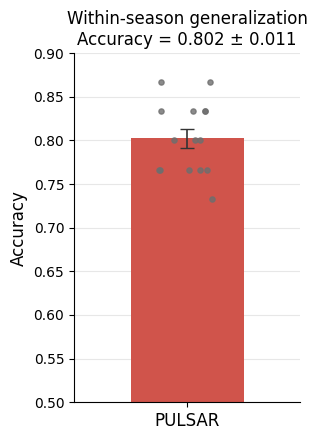

In [9]:
fig, ax = plt.subplots(figsize=(3.2, 4.5))
ax.bar([0], [acc_mean], width=0.6, color="#D0544B", zorder=2)
ax.errorbar([0], [acc_mean], yerr=[acc_sem], fmt="none", ecolor="#333333", elinewidth=1.2, capsize=5, zorder=4)
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(test_accuracies))
ax.scatter(jitter, test_accuracies, s=14, color="#6E6E6E", alpha=0.8, zorder=3)
ax.set_xticks([0])
ax.set_xticklabels(["PULSAR"], fontsize=12)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(0.5, 0.9)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title(f"Within-season generalization\nAccuracy = {acc_mean:.3f} ± {acc_sem:.3f}", fontsize=12)
ax.grid(axis="y", alpha=0.3, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()